# Quantum Fourier Transform vs Classical FFT: Implementation and Comparison

This notebook builds on the reusable modules in `src/`. It uses local Qiskit `Statevector` simulation only; no IBM account or remote quantum backend is needed. The quantum input vector is normalized before it is treated as a state.

## 1. Discrete Fourier Transform (DFT)

For a length-`N` sequence `x`, the positive-exponent DFT used in this project is `X[k] = (1/sqrt(N)) * sum_j x[j] exp(+2*pi*i*j*k/N)`. The normalization makes the transform unitary. This sign convention is important: it is the inverse-DFT convention used by NumPy, so the matching classical expression is `np.fft.ifft(x) * np.sqrt(N)`, **not** `np.fft.fft(x)`.

For comparison, the usual classical forward DFT uses the negative exponent. The naive implementation evaluates every output against every input and therefore costs `O(N^2)` arithmetic operations.

## 2. Classical FFT

The Cooley–Tukey Fast Fourier Transform (FFT) factors a transform into smaller transforms and reuses intermediate results. For power-of-two input sizes this reduces work from `O(N^2)` for a naive DFT to `O(N log2(N))`. In the plots and exact amplitude comparison, the classical reference follows the same positive-exponent convention as the QFT circuit.

## 3. Quantum Fourier Transform (QFT)

For `N = 2^n`, the QFT maps a basis state as `|x> -> (1/sqrt(N)) sum_y exp(+2*pi*i*x*y/N) |y>`. By linearity, it transforms a normalized amplitude vector. In this notebook, `Statevector(x).evolve(qft(n)).data` is compared to `np.fft.ifft(x) * np.sqrt(N)`. Always normalize arbitrary input data (`x / np.linalg.norm(x)`) before constructing a quantum state.

## 4. Circuit structure and gate complexity

The circuit is implemented manually: each qubit receives a Hadamard gate, controlled phase rotations add the relative phases, and final swaps undo the bit-reversed wire ordering. The circuit uses `n` Hadamards and `n(n-1)/2` controlled-phase gates, totaling `n(n+1)/2` H+CP gates, plus `floor(n/2)` swaps. Thus it needs `O(n^2)` gates, or `O((log N)^2)` when written in terms of the number of amplitudes. The module does not use Qiskit's `QFT` or `QFTGate` library circuits.

In [19]:
from pathlib import Path
import sys

# Find the project root even when the notebook is launched from another cwd.
working_dir = Path.cwd()
candidates = [working_dir, *working_dir.parents, working_dir / "qft_vs_fft"]
PROJECT_ROOT = next(
    (path for path in candidates if (path / "src").is_dir() and (path / "notebooks" / "qft_vs_fft.ipynb").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate qft_vs_fft/src from the notebook working directory")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
from IPython.display import Markdown, display
from qiskit.quantum_info import Operator, Statevector

from src.classical_fft import naive_dft, numpy_fft, numpy_qft_reference
from src.compare import comparison_cases, correctness_results, normalize
from src.plots import (
    plot_circuit_depth,
    plot_complexity,
    plot_measurement_limitation,
    plot_periodic_signal,
    plot_qft_vs_classical,
    plot_timing,
    save_circuit_diagrams,
)
from src.quantum_qft import inverse_qft, qft

RESULTS_DIR = PROJECT_ROOT / "results"
RESULTS_DIR.mkdir(exist_ok=True)
print(f"Project root: {PROJECT_ROOT}")
print(f"Figures will be saved in: {RESULTS_DIR}")

Project root: d:\Trishna Projects\quantum\qft_vs_fft
Figures will be saved in: d:\Trishna Projects\quantum\qft_vs_fft\results


## 5. Correctness comparison for one to five qubits

For every `n` from 1 through 5, compare a random complex vector, a computational-basis state, a uniform superposition, and a periodic cosine. Inputs are normalized before the QFT. The classical comparison is `ifft(x) * sqrt(N)` to match the positive-exponent QFT, and `np.allclose` is used for the match decision.

In [20]:
results = correctness_results(min_qubits=1, max_qubits=5, seed=42)
results_table = [
    "| n | N | input | match | max error |",
    "|---:|---:|---|:---:|---:|",
]
results_table.extend(
    f"| {row['n']} | {row['N']} | {row['input']} | {row['match']} | {row['max_error']:.3e} |"
    for row in results
)
display(Markdown("\n".join(results_table)))
print("Every row matches:", all(row["match"] for row in results))
print("Largest absolute error:", f"{max(row['max_error'] for row in results):.3e}")

| n | N | input | match | max error |
|---:|---:|---|:---:|---:|
| 1 | 2 | random complex | True | 2.289e-16 |
| 1 | 2 | basis state | True | 1.110e-16 |
| 1 | 2 | uniform | True | 2.220e-16 |
| 1 | 2 | periodic cosine | True | 2.220e-16 |
| 2 | 4 | random complex | True | 1.144e-16 |
| 2 | 4 | basis state | True | 1.152e-16 |
| 2 | 4 | uniform | True | 2.220e-16 |
| 2 | 4 | periodic cosine | True | 1.110e-16 |
| 3 | 8 | random complex | True | 2.289e-16 |
| 3 | 8 | basis state | True | 1.131e-16 |
| 3 | 8 | uniform | True | 3.331e-16 |
| 3 | 8 | periodic cosine | True | 2.220e-16 |
| 4 | 16 | random complex | True | 1.862e-16 |
| 4 | 16 | basis state | True | 1.178e-16 |
| 4 | 16 | uniform | True | 3.331e-16 |
| 4 | 16 | periodic cosine | True | 2.220e-16 |
| 5 | 32 | random complex | True | 2.253e-16 |
| 5 | 32 | basis state | True | 1.084e-16 |
| 5 | 32 | uniform | True | 4.441e-16 |
| 5 | 32 | periodic cosine | True | 3.331e-16 |

Every row matches: True
Largest absolute error: 4.441e-16


## 6. Inspecting the manually built circuits

The two requested diagrams show the individual gates. The circuit is written in code rather than imported from Qiskit's QFT library. The swaps at the end restore the usual frequency-index ordering.

results\qft_circuit_n3.png
results\qft_circuit_n4.png


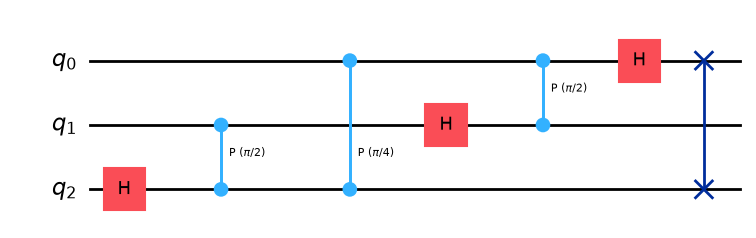

In [21]:
circuit_paths = save_circuit_diagrams(RESULTS_DIR)
for path in circuit_paths:
    print(path.relative_to(PROJECT_ROOT))
qft(3).draw("mpl", fold=-1)

## 7. Magnitude and phase comparison

The following figure compares complex output amplitudes, not merely their probabilities. Its classical series is the positive-exponent QFT reference `np.fft.ifft(x) * sqrt(N)`. Phase comparisons are meaningful even though measurement alone cannot reveal those phases.

In [22]:
comparison_signal = comparison_cases(3, np.random.default_rng(314))["random complex"]
magnitude_phase_path = plot_qft_vs_classical(comparison_signal, RESULTS_DIR)
print(magnitude_phase_path.relative_to(PROJECT_ROOT))

results\qft_vs_classical_magnitude_phase.png


## 8. Periodic signal and frequency peaks

A cosine with frequency bin `f` contains positive and negative frequency components, so its QFT magnitude has peaks at bins `f` and `N-f` (with coincident bins for special cases). Here `N=16` and `f=4`; the period divides the sample length.

In [23]:
periodic_path = plot_periodic_signal(RESULTS_DIR, n=4)
print(periodic_path.relative_to(PROJECT_ROOT))

results\periodic_signal_spectrum.png


## 9. Complexity and circuit depth

The QFT curve counts H, controlled-phase, and swap gates from actual circuits for small `n`, then uses the exact gate formula for larger `n`. The classical curves show operation-count scaling, not wall-clock timings. The depth plot is computed from each actual, untranspiled QFT circuit.

In [24]:
complexity_path = plot_complexity(RESULTS_DIR)
depth_path = plot_circuit_depth(RESULTS_DIR)
print(complexity_path.relative_to(PROJECT_ROOT))
print(depth_path.relative_to(PROJECT_ROOT))

results\complexity_comparison.png
results\circuit_depth.png


## 10. Timing: classical FFT versus local statevector simulation

This measures the NumPy FFT and Qiskit statevector evolution on the same normalized vectors. A statevector simulator is a classical algorithm that explicitly tracks `N=2^n` complex amplitudes, so simulating a QFT is not the same as running it on quantum hardware. Timings are machine- and load-dependent and are included to illustrate trends, not as a hardware benchmark.

In [25]:
timing_path, timings = plot_timing(RESULTS_DIR, max_qubits=14)
print(timing_path.relative_to(PROJECT_ROOT))
timing_rows = ["| n | N | NumPy FFT (s) | Statevector QFT (s) |", "|---:|---:|---:|---:|"]
timing_rows.extend(
    f"| {row['n']} | {row['N']} | {row['numpy_fft_seconds']:.3e} | {row['statevector_seconds']:.3e} |"
    for row in timings
)
display(Markdown("\n".join(timing_rows)))

results\runtime_comparison.png


| n | N | NumPy FFT (s) | Statevector QFT (s) |
|---:|---:|---:|---:|
| 1 | 2 | 3.320e-05 | 2.187e-04 |
| 2 | 4 | 2.320e-05 | 3.341e-04 |
| 3 | 8 | 2.230e-05 | 4.194e-04 |
| 4 | 16 | 2.430e-05 | 7.150e-04 |
| 5 | 32 | 2.780e-05 | 9.800e-04 |
| 6 | 64 | 3.240e-05 | 1.751e-03 |
| 7 | 128 | 2.180e-05 | 1.009e-03 |
| 8 | 256 | 1.920e-05 | 1.563e-03 |
| 9 | 512 | 2.470e-05 | 1.558e-03 |
| 10 | 1024 | 2.420e-05 | 1.936e-03 |
| 11 | 2048 | 3.200e-05 | 2.587e-03 |
| 12 | 4096 | 5.030e-05 | 3.868e-03 |
| 13 | 8192 | 9.310e-05 | 6.293e-03 |
| 14 | 16384 | 1.841e-04 | 2.882e-02 |

## 11. Measurement limitation

A measurement collapses the state and returns a sampled basis outcome. Repeated shots estimate `|amplitude|^2`; they do not return the complex amplitudes, including their phase. The plot compares exact probabilities with frequencies from 1024 local `Statevector.sample_counts` shots.

In [26]:
measurement_path = plot_measurement_limitation(comparison_signal, RESULTS_DIR, shots=1024)
print(measurement_path.relative_to(PROJECT_ROOT))

results\measurement_probabilities.png


## 12. Inverse-QFT check

The inverse circuit is obtained by inverting the manually built QFT. Applying QFT and then inverse QFT must recover the starting amplitudes. The operator-level test checks the stronger identity `inverse_qft(n) @ qft(n) = I`.

In [27]:
n = 3
input_state = normalize(np.array([1, 2j, -1, 0.5, 1j, 2, -0.5j, 1], dtype=complex))
recovered = Statevector(input_state).evolve(qft(n)).evolve(inverse_qft(n)).data
operator_product = Operator(qft(n).compose(inverse_qft(n))).data
print("Maximum recovery error:", f"{np.max(np.abs(recovered - input_state)):.3e}")
print("Operator identity:", np.allclose(operator_product, np.eye(2**n)))
print("Recovered input:", np.allclose(recovered, input_state))

Maximum recovery error: 3.333e-16
Operator identity: True
Recovered input: True


## Limitations and interpretation

1. **Amplitude readout is not available:** measurement collapses the state. Samples reveal probabilities, not the complex amplitudes that a classical FFT returns.
2. **State preparation can be expensive:** encoding an arbitrary length-`N` classical vector as amplitudes may require `O(N)` gates/resources.
3. **Not a drop-in FFT replacement:** the QFT has `O(n^2)` gates for `N=2^n`, but extracting all output data costs many measurements. Its advantage is as a subroutine within larger quantum algorithms, especially phase estimation and Shor's algorithm.

The apparent operation-count advantage therefore does not imply that a QFT solves general classical Fourier-transform tasks faster end-to-end.

## Conclusion

The hand-built Hadamard, controlled-phase, and swap circuit implements the positive-exponent QFT and matches `np.fft.ifft(x) * sqrt(N)` on normalized test inputs. The classical FFT remains the practical tool for obtaining all Fourier coefficients from classical data. The QFT's significance is its role inside quantum algorithms, where amplitudes can be processed coherently and only selected information needs to be measured.

## Viva Q&A

1. **What is the DFT?** It maps a finite sequence to frequency coefficients using sums of complex roots of unity.
2. **How does an FFT differ from a DFT?** The FFT is an efficient algorithm for computing the same transform; Cooley–Tukey reduces the work to `O(N log N)` for suitable lengths.
3. **What does the QFT do to a basis state?** It creates an equal-magnitude superposition whose phases encode the input index.
4. **Why is the reference `ifft(x) * sqrt(N)`?** This circuit uses a positive exponent and unitary normalization, matching NumPy's inverse FFT sign and scaling.
5. **Why normalize the input vector?** Quantum state amplitudes must have squared magnitudes summing to one.
6. **Which gates implement this QFT?** Hadamards create superpositions, controlled-phase rotations encode relative phases, and swaps restore standard bit order.
7. **Why does the circuit use `O(n^2)` gates?** There are `n` Hadamards and `n(n-1)/2` controlled-phase gates, plus only linearly many swaps.
8. **Can one measurement read all QFT amplitudes?** No. Measurement collapses the state and yields one sampled outcome; repeated shots estimate probabilities, not complex amplitudes.
9. **Why isn't QFT a replacement for classical FFT?** Arbitrary input-state preparation may cost `O(N)`, and recovering all output coefficients requires many measurements.
10. **Where is QFT useful?** As a subroutine in quantum phase estimation and Shor's factoring algorithm, where the output structure reveals useful information.